<a href="https://colab.research.google.com/github/cxg1149/beginning-bioinformatics/blob/main/Breast_Cancer_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Revisiting Breast Cancer Cytology: Mean Versus Extreme Nuclear Morphology in Machine Learning Classification

Research question: Do extreme nuclear morphology measurements provide better classification performance than mean measurements?

Dataset: Wisconsin Diagnostic Breast Cancer (UCI Machine Learning Repository).




In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_breast_cancer

# Load the Wisconsin Diagnostic Breast Cancer dataset
data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# Recode labels so 1 = malignant, 0 = benign
y = (data.target == 0).astype(int)

print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("\nDiagnosis counts:")
print(y.map({0: "Benign", 1: "Malignant"}).value_counts())
print("\nMissing values:", X.isna().sum().sum())
print("\nscikit-learn version:", sklearn.__version__)

display(X.head())


Number of samples: 569
Number of features: 30

Diagnosis counts:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Missing values: 0

scikit-learn version: 1.6.1


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:

# Separate features by measurement type
mean_features = [
    col for col in X.columns
    if col.startswith("mean ")
]

worst_features = [
    col for col in X.columns
    if col.startswith("worst ")
]

feature_groups = {
    "Mean": mean_features,
    "Worst": worst_features,
    "All": list(X.columns)
}

for group, features in feature_groups.items():
    print(f"{group}: {len(features)} features")
    print(features[:3], "\n")


Mean: 10 features
['mean radius', 'mean texture', 'mean perimeter'] 

Worst: 10 features
['worst radius', 'worst texture', 'worst perimeter'] 

All: 30 features
['mean radius', 'mean texture', 'mean perimeter'] 



In [4]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

metrics = {
    "Accuracy": "accuracy",
    "Sensitivity": "recall",
    "Precision": "precision",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

results = []

for group_name, columns in feature_groups.items():
    X_group = X[columns]

    for model_name, model in models.items():
        scores = cross_validate(
            model,
            X_group,
            y,
            cv=cv,
            scoring=metrics
        )

        row = {
            "Feature Group": group_name,
            "Model": model_name
        }

        for metric in metrics:
            row[metric] = scores[
                f"test_{metric}"
            ].mean()

        results.append(row)

results_df = pd.DataFrame(results)
display(results_df.round(3))


,Feature Group,Model,Accuracy,Sensitivity,Precision,F1,ROC-AUC
0,Mean,Logistic Regression,0.940,0.901,0.938,0.917,0.987
1,Mean,Random Forest,0.942,0.915,0.933,0.922,0.985
2,Worst,Logistic Regression,0.979,0.962,0.982,0.971,0.993
3,Worst,Random Forest,0.961,0.925,0.971,0.946,0.988
4,All,Logistic Regression,0.974,0.944,0.986,0.963,0.995
5,All,Random Forest,0.954,0.934,0.946,0.938,0.990


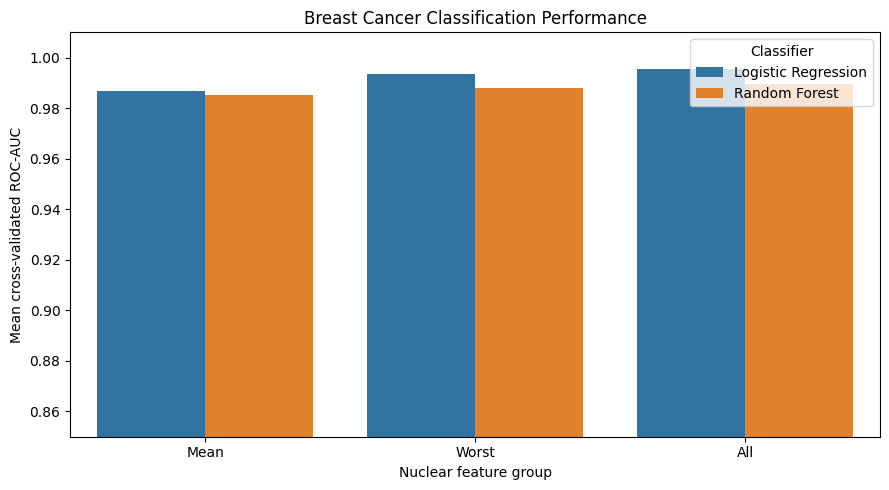

In [5]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Feature Group",
    y="ROC-AUC",
    hue="Model",
    order=["Mean", "Worst", "All"]
)

plt.ylim(0.85, 1.01)
plt.ylabel("Mean cross-validated ROC-AUC")
plt.xlabel("Nuclear feature group")
plt.title("Breast Cancer Classification Performance")
plt.legend(title="Classifier")
plt.tight_layout()

plt.savefig(
    "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:

results_df.to_csv(
    "model_results.csv",
    index=False
)

print("Results saved successfully.")


Results saved successfully.


In [7]:

# Sort models by ROC-AUC
ranked_results = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(ranked_results.round(4))

# Identify highest-scoring model
best_model = ranked_results.iloc[0]

print("Highest mean ROC-AUC:")
print(best_model["Model"])
print("Feature group:", best_model["Feature Group"])
print("ROC-AUC:", round(best_model["ROC-AUC"], 4))


,Feature Group,Model,Accuracy,Sensitivity,Precision,F1,ROC-AUC
4,All,Logistic Regression,0.9737,0.9436,0.9863,0.9633,0.9953
2,Worst,Logistic Regression,0.9789,0.9625,0.9820,0.9712,0.9935
5,All,Random Forest,0.9543,0.9341,0.9463,0.9382,0.9896
3,Worst,Random Forest,0.9613,0.9248,0.9713,0.9459,0.9880
0,Mean,Logistic Regression,0.9403,0.9008,0.9379,0.9175,0.9869
1,Mean,Random Forest,0.9420,0.9151,0.9333,0.9217,0.9853


Highest mean ROC-AUC:
Logistic Regression
Feature group: All
ROC-AUC: 0.9953


In [1]:

import sys
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)


Python: 3.13.18
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
